In [1]:
# Install required packages
!pip install pandas numpy matplotlib seaborn scikit-learn nltk


In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.svm import LinearSVC

import re
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
# Set the file path (update this to match your Google Drive location)
file_path = '/content/drive/MyDrive/Dataset.csv'

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Drop the 'Unnamed: 0' column if it exists (often created when saving from Excel/CSV)
if 'Unnamed: 0' in df.columns:
    df.drop('Unnamed: 0', axis=1, inplace=True)

# Display the first 5 rows
df.head()

,text,Emotion
0,i seriously hate one subject to death but now ...,hate
1,im so full of life i feel appalled,neutral
2,i sit here to write i start to dig out my feel...,neutral
3,ive been really angry with r and i feel like a...,anger
4,i feel suspicious if there is no one outside l...,neutral


In [19]:
# Check the shape of the dataset (rows, columns)
df.shape


(839555, 2)

In [20]:
# See how many missing values are in each column
df.isnull().sum()

,0
text,0
Emotion,0


In [21]:
# Look at how many samples we have for each emotion
df['Emotion'].value_counts()

,count
Emotion,
neutral,674538
love,39553
happiness,27175
sadness,17481
relief,16729
hate,15267
anger,12336
fun,10075
enthusiasm,9304


In [24]:
# Text preprocessing
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

# Apply preprocessing
df['clean_text'] = df['text'].apply(preprocess_text)


In [25]:
# Convert emotion labels into numeric values
label_encoder = LabelEncoder()
df['encoded_emotion'] = label_encoder.fit_transform(df['Emotion'])


In [26]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],                # Features (text)
    df['encoded_emotion'],           # Target (encoded emotions)
    test_size=0.3,                   # 70% train / 30% test
    random_state=42,                 # Reproducibility
    stratify=df['encoded_emotion']   # Keep class balance
)


In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    max_features=10000,    # Limit to top 10k features
    ngram_range=(1, 2)     # Use unigrams + bigrams
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [28]:
# Number of unique emotion classes
num_classes = len(label_encoder.classes_)
num_classes


13

In [29]:
# Initialize Logistic Regression model
log_reg = LogisticRegression(
    max_iter=500,          # Increase iterations for convergence
    class_weight="balanced", # Handle imbalanced classes
    n_jobs=-1              # Use all CPU cores
)

# Train the model on TF-IDF features
log_reg.fit(X_train_tfidf, y_train)


LogisticRegression(class_weight='balanced', max_iter=500, n_jobs=-1)

In [30]:
# Predict emotions on the test set
y_pred_lr = log_reg.predict(X_test_tfidf)


In [31]:
# Show precision, recall, F1-score for each class
print("=== Logistic Regression Report ===")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))


=== Logistic Regression Report ===
              precision    recall  f1-score   support

       anger       0.97      0.97      0.97      3701
     boredom       0.68      0.95      0.79        38
       empty       0.97      0.98      0.98      1663
  enthusiasm       1.00      0.98      0.99      2791
         fun       0.89      0.95      0.92      3022
   happiness       0.99      0.99      0.99      8153
        hate       0.99      0.99      0.99      4580
        love       1.00      0.99      0.99     11866
     neutral       1.00      1.00      1.00    202362
      relief       0.97      0.96      0.96      5019
     sadness       1.00      0.97      0.98      5244
    surprise       0.99      0.99      0.99      2086
       worry       0.93      1.00      0.96      1342

    accuracy                           0.99    251867
   macro avg       0.95      0.98      0.96    251867
weighted avg       0.99      0.99      0.99    251867



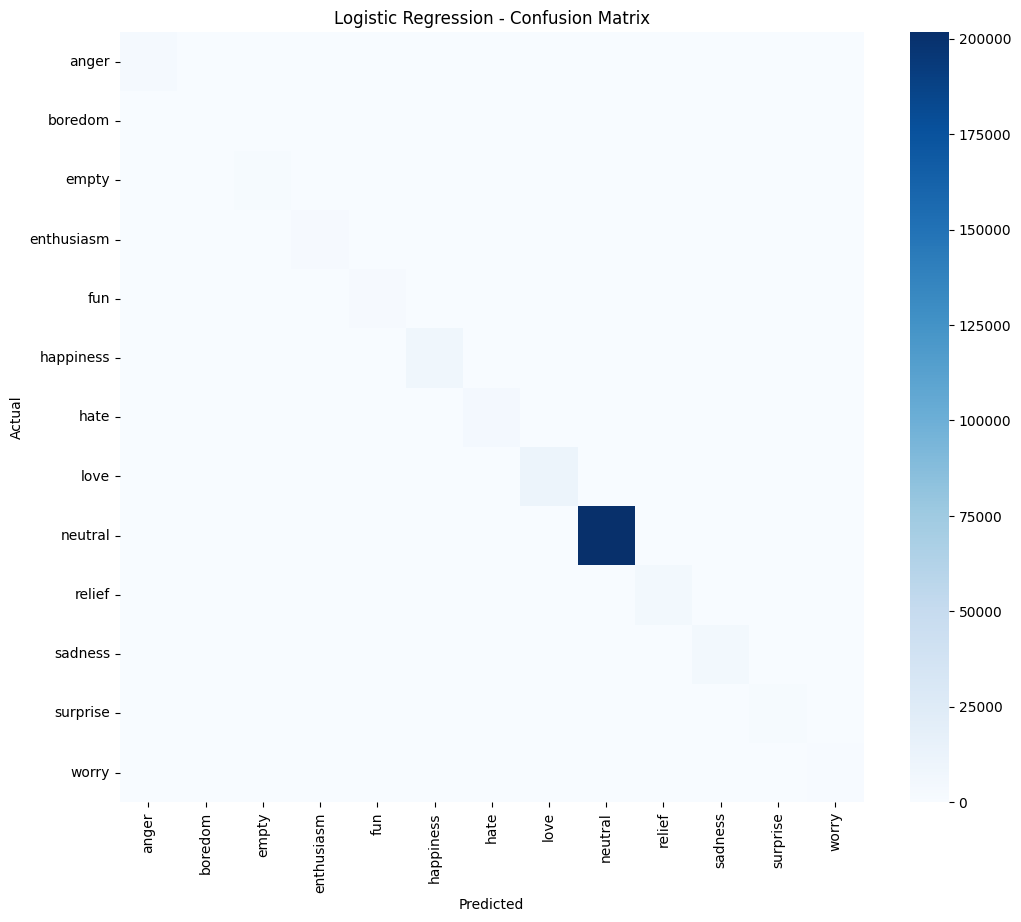

In [32]:
# Compute confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_lr,
    annot=False,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [33]:
# Evaluate overall performance
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr, average="weighted"))
print("Precision:", precision_score(y_test, y_pred_lr, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_lr, average="weighted"))


Accuracy: 0.9931312954853156
F1 Score: 0.9931627600079549
Precision: 0.99324712172982
Recall: 0.9931312954853156


In [34]:
from sklearn.svm import LinearSVC

# Initialize LinearSVC (efficient SVM for text classification)
svm_model = LinearSVC(
    class_weight="balanced",  # Handle imbalanced classes
    max_iter=2000             # Increase iterations for convergence
)

# Train the SVM model on TF-IDF features
svm_model.fit(X_train_tfidf, y_train)


LinearSVC(class_weight='balanced', max_iter=2000)

In [35]:
# Predict emotions on the test set using SVM
y_pred_svm = svm_model.predict(X_test_tfidf)


In [36]:
# Show precision, recall, F1-score for each class
print("=== Support Vector Machine Report ===")
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))


=== Support Vector Machine Report ===
              precision    recall  f1-score   support

       anger       0.99      0.97      0.98      3701
     boredom       1.00      0.89      0.94        38
       empty       1.00      0.98      0.99      1663
  enthusiasm       1.00      0.99      0.99      2791
         fun       0.99      0.94      0.97      3022
   happiness       1.00      0.99      0.99      8153
        hate       1.00      0.99      0.99      4580
        love       1.00      0.99      0.99     11866
     neutral       1.00      1.00      1.00    202362
      relief       0.99      0.96      0.98      5019
     sadness       1.00      0.97      0.99      5244
    surprise       1.00      0.99      0.99      2086
       worry       0.94      0.99      0.97      1342

    accuracy                           1.00    251867
   macro avg       0.99      0.97      0.98    251867
weighted avg       1.00      1.00      1.00    251867



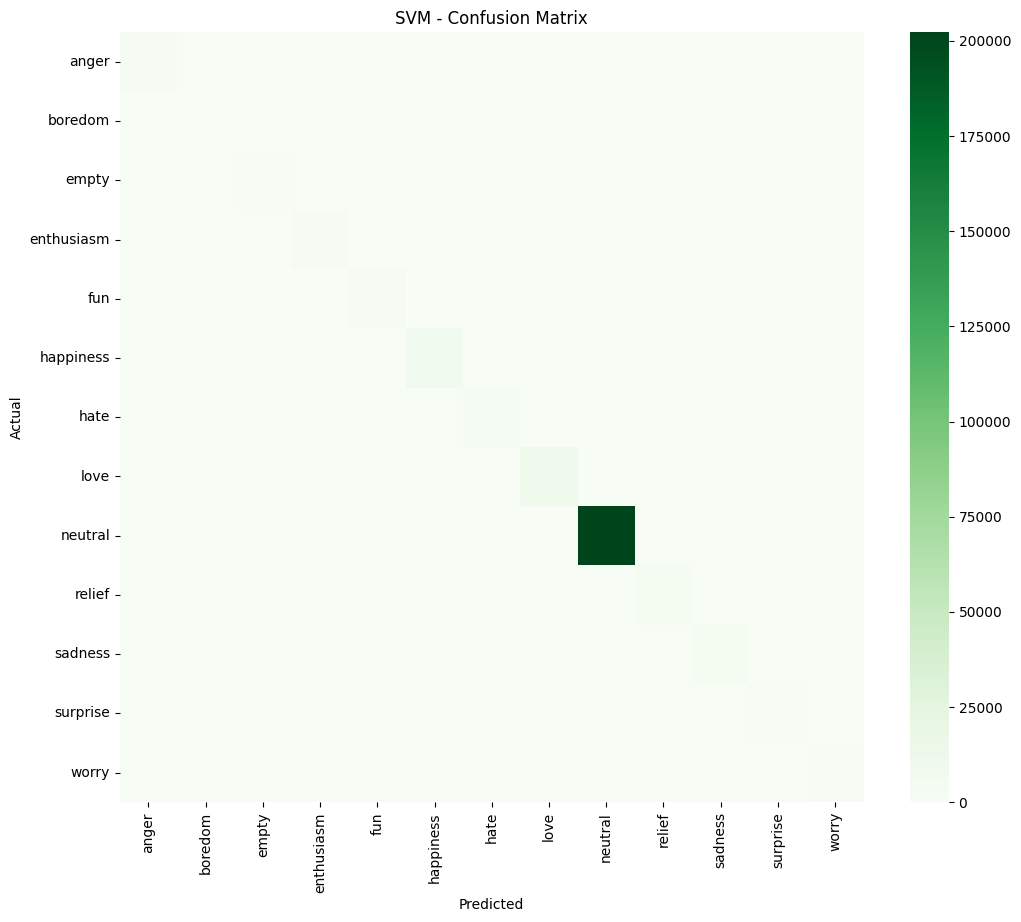

In [37]:
# Compute confusion matrix for SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_svm,
    annot=False,            # Set True to show numbers on heatmap
    cmap="Greens",          # Use green color map
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [38]:
# Evaluate overall performance of SVM
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm, average="weighted"))
print("Precision:", precision_score(y_test, y_pred_svm, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_svm, average="weighted"))


Accuracy: 0.9956643784219449
F1 Score: 0.9956428745614591
Precision: 0.9956762099411005
Recall: 0.9956643784219449


In [16]:
import joblib

# Save trained models
joblib.dump(log_reg, "logistic_regression_model.pkl")
joblib.dump(svm_model, "svm_model.pkl")

# Save vectorizer and label encoder
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Models, vectorizer, and encoder saved successfully!")


Models, vectorizer, and encoder saved successfully!
